<a href="https://colab.research.google.com/github/Sands225/Coral-Disease-Classification/blob/main/%5BSistem_Cerdas%5D_Coral_Disease_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Coral Disease Detection

**Mata Kuliah**: \
Sistem Cerdas A

\
**Dosen Pengampu**: \
Pak Agus Surya Darma

\
**Anggota Kelompok**:
| NIM | Nama |
| --- | --- |
| - | Naren |
| - | Satya |
| 2405551082 | I Made Sandika Wijaya

In [ ]:
!pip install roboflow ultralytics

In [ ]:
from roboflow import Roboflow

import os
from glob import glob
from PIL import Image
import matplotlib.pyplot as plt

## Data Collection
Tahapan ini merupakan tahapan pengumpulan data yang akan digunakan pada eksperimen ini. \
Dataset yang digunakan bersumber dari Roboflow, yaitu
[Marjan Detection v7](
https://universe.roboflow.com/maha-bil6y/marjan-detection/dataset/7)

In [ ]:
# Setup untuk mengunduh dataset dari Roboflow
from google.colab import userdata
ROBOFLOW_KEY = userdata.get('ROBOFLOW_KEY')

rf = Roboflow(api_key=ROBOFLOW_KEY)
project = rf.workspace("maha-bil6y").project("marjan-detection")
version = project.version(7)
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to marjan-detection-7 in yolov11:: 100%|██████████| 6209/6209 [00:03<00:00, 1731.45it/s]


In [ ]:
dataset_path = "/content/marjan-detection-7"

for root, dirs, files in os.walk(dataset_path):
  level = root.replace(dataset_path, "").count(os.sep)
  indent = " " * 4 * level
  print(f"{indent}{os.path.basename(root)}/")

  for file in files[:5]:
    print(f"{indent}    {file}")

marjan-detection-7/
    README.roboflow.txt
    README.dataset.txt
    data.yaml
    valid/
        images/
            457_jpg.rf.de12d967a271fb9ec43aabbc96bef8c3.jpg
            438_jpg.rf.f9fade0ee6fb8252fa741720fbf7351c.jpg
            256_png_jpg.rf.1bdf0da7769414c6e196e1256b29c7cb.jpg
            14164148280_5a30747885_o_jpg.rf.5f1689932d511971051ce414d9c7c645.jpg
            free-living-13_jpg.rf.2c3e6dcc3613d21623b77af3dc481fb0.jpg
        labels/
            qr0y3lofg7-JPG-800x0_q85_jpg.rf.e62f399e991f2731251a7f2d4149bc60.txt
            18206069405_acac2f12e6_o_jpg.rf.5e14d8175ad75b712decc0d559fae78b.txt
            d2ou0vk056-JPG-800x0_q85_jpg.rf.52f2da27b45fb3c49d50b0b8bd8c9797.txt
            Bleach_5_jpg.rf.4c57abb5ee8db5e32015434786b70ab3.txt
            96_png_jpg.rf.f6cefe81c04d9bb358094e0f7d95be40.txt
    train/
        images/
            231_jpg.rf.82549f4de144b1379ff073f5a9c95545.jpg
            91_jpg.rf.a833d9ea72f5882f5aec400d3cd8d1c9.jpg
            4674521434_

In [ ]:
dataset_path = "/content/marjan-detection-7"

# Cari semua file gambar di dalam dataset
image_extensions = ["*.jpg", "*.jpeg", "*.png", "*.webp"]
image_files = []

for ext in image_extensions:
  image_files.extend(
    glob(os.path.join(dataset_path, "**", ext), recursive=True)
  )

print("Jumlah gambar:", len(image_files))
print("Contoh gambar:", image_files[:5])

Jumlah gambar: 3102
Contoh gambar: ['/content/marjan-detection-7/valid/images/457_jpg.rf.de12d967a271fb9ec43aabbc96bef8c3.jpg', '/content/marjan-detection-7/valid/images/438_jpg.rf.f9fade0ee6fb8252fa741720fbf7351c.jpg', '/content/marjan-detection-7/valid/images/256_png_jpg.rf.1bdf0da7769414c6e196e1256b29c7cb.jpg', '/content/marjan-detection-7/valid/images/14164148280_5a30747885_o_jpg.rf.5f1689932d511971051ce414d9c7c645.jpg', '/content/marjan-detection-7/valid/images/free-living-13_jpg.rf.2c3e6dcc3613d21623b77af3dc481fb0.jpg']


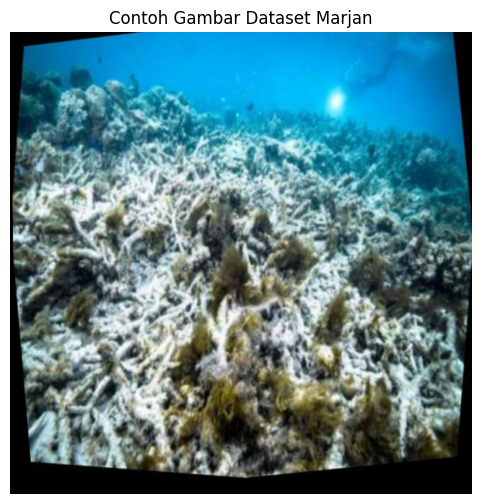

In [ ]:
img = Image.open(image_files[0])

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.axis("off")
plt.title("Contoh Gambar Dataset Marjan")
plt.show()

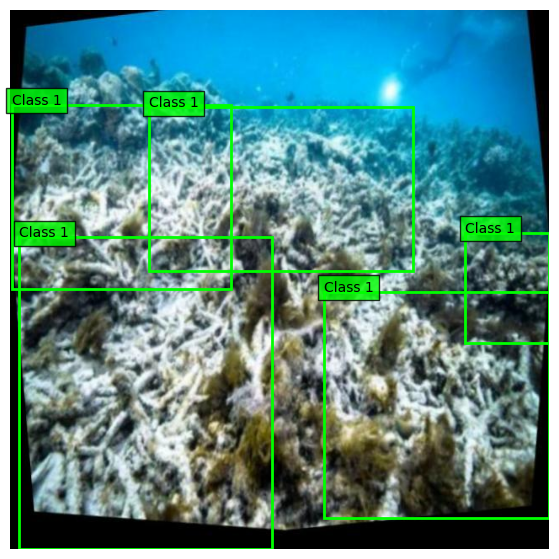

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path

# Ambil gambar pertama
image_path = Path(image_files[0])
img = Image.open(image_path).convert("RGB")
img_width, img_height = img.size

# Cari file label dengan nama yang sama
label_path = None

for candidate in Path(dataset_path).rglob("*.txt"):
    if candidate.stem == image_path.stem:
        label_path = candidate
        break

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(img)

if label_path is not None:
    with open(label_path, "r") as f:
        for line in f:
            values = line.split()

            if len(values) != 5:
                continue

            class_id, xc, yc, w, h = map(float, values)

            # Koordinat ternormalisasi menjadi piksel
            xc *= img_width
            yc *= img_height
            w *= img_width
            h *= img_height

            x = xc - w / 2
            y = yc - h / 2

            rect = patches.Rectangle(
                (x, y), w, h,
                linewidth=2,
                edgecolor="lime",
                facecolor="none"
            )

            ax.add_patch(rect)
            ax.text(x, y, f"Class {int(class_id)}",
                    color="black",
                    bbox=dict(facecolor="lime", alpha=0.8))

else:
    print("File label tidak ditemukan untuk gambar ini.")

ax.axis("off")
plt.show()


In [ ]:

from pathlib import Path

yaml_files = list(Path(dataset_path).rglob("data.yaml"))

for yaml_file in yaml_files:
    print(f"File: {yaml_file}")
    print(yaml_file.read_text())


File: /content/marjan-detection-7/data.yaml
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['Bleached Coral', 'Dead Coral', 'Healthy Coral']

roboflow:
  workspace: maha-bil6y
  project: marjan-detection
  version: 7
  license: CC BY 4.0
  url: https://universe.roboflow.com/maha-bil6y/marjan-detection/dataset/7


In [ ]:
from pathlib import Path

dataset_path = Path("/content/marjan-detection-7")

for p in dataset_path.rglob("data.yaml"):
  print(p)
  print(p.read_text())

/content/marjan-detection-7/data.yaml
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['Bleached Coral', 'Dead Coral', 'Healthy Coral']

roboflow:
  workspace: maha-bil6y
  project: marjan-detection
  version: 7
  license: CC BY 4.0
  url: https://universe.roboflow.com/maha-bil6y/marjan-detection/dataset/7


In [ ]:
from ultralytics import YOLO

data_yaml = "/content/marjan-detection-7/data.yaml"

# Memuat bobot pretrained YOLO11 nano
model = YOLO("yolo11n.pt")

results = model.train(
    data=data_yaml,
    epochs=50,
    imgsz=640,
    batch=16,
    patience=10,
    project="runs/marjan",
    name="yolo11n_baseline",
    seed=42
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.174 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (AMD EPYC 7B12)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/marjan-detection-7/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fr

In [ ]:
metrics = model.val(data=data_yaml)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)